# Revenue Analysis for Solstice Opal Hotel

### Objective

Identify which guest segments generate the highest ancillary revenue and recommend actions to maximise future revenue.

In [12]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

ancillary_spend= pd.read_csv('data/da_sample_ancillary_spend.csv')
guest_profiles= pd.read_csv('data/da_sample_guest_profiles.csv')
stay_details= pd.read_csv('data/da_sample_stay_details.csv')

## Data Validation
- Data validation was performed to ensure consistency and reliability across the three source systems (guest profiles, stay details, and ancillary spend).
  
- The guest_id format in ancillary_spend was standardised using regex extraction to align with the other source tables.
  
- Missing values across all datasets were identified and standardised to NaN to ensure consistent handling during analysis.
  
- Categorical variables, including loyalty_tier, booking_channel, and reason_for_stay, were validated against expected domain definitions, with no unexpected categories observed, confirming data consistency across systems.
  
- The check_in_date field was converted into datetime format to ensure temporal consistency for time-based analysis.
  
- A sanity check confirmed that amount_spent contained no negative values, ensuring the integrity of revenue data.
  
- Due to differences in granularity between transaction-level ancillary spend and stay-level data, the analysis was aggregated at guest level to create a consistent basis for behavioural segmentation. Guest-level aggregation was used to compare spending patterns across different customer segments.

In [13]:
stay_details['check_in_date']= pd.to_datetime(stay_details['check_in_date'])
ancillary_spend['guest_id']= ancillary_spend['guest_id'].str.extract(r'(\d+)').astype(int)
stay_details['stay_id']= stay_details['stay_id'].astype('string')

replace_values= ['',' ','na','Na','NA','NaN','n/a','N/A','null','NULL']
ancillary_spend= ancillary_spend.replace(replace_values,np.nan)
guest_profiles= guest_profiles.replace(replace_values,np.nan)
stay_details= stay_details.replace(replace_values,np.nan)
#print(ancillary_spend.head(),guest_profiles.head(),stay_details.head())

hotel_merge= ancillary_spend.merge(stay_details, on='guest_id').merge(guest_profiles, on='guest_id', )
#print(hotel_merge.info())

hotel_merge.isna().sum()
hotel_merge.duplicated().sum()
hotel_merge.describe()
hotel_merge['loyalty_tier'].unique()
hotel_merge['reason_for_stay'].unique()
hotel_merge['booking_channel'].unique()
hotel_merge['category'].unique()

guest_level= hotel_merge.groupby('guest_id').agg({
    'amount_spent':'sum','booking_channel': lambda x: x.mode().iloc[0] if len(x.mode()) > 0 else np.nan,
    'loyalty_tier': lambda x: x.mode().iloc[0] if len(x.mode()) > 0 else np.nan,
    'reason_for_stay': lambda x: x.mode().iloc[0] if len(x.mode()) > 0 else np.nan,
    'number_of_guests': 'mean',
    'category': lambda x: x.mode().iloc[0] if len(x.mode()) > 0 else np.nan}).reset_index()
#print(guest_level.head())
#print(guest_level.isna().sum())

## Business Metric
Average Revenue Per Guest (ARPG)

- Definition
Average ancillary revenue generated by each guest.
-  Formula
Total ancillary revenue / Number of guests

Current Average Ancillary Revenue per Guest (ARPG) : $390.22
Most guests spend relatively small amounts while a few guests spend considerably more, indicating a right-skewed distribution.


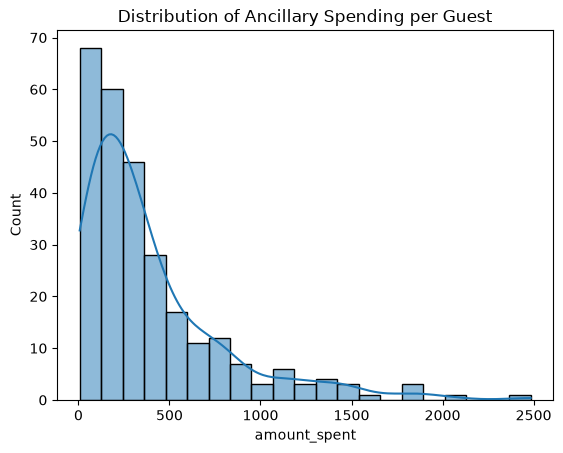

In [14]:
#ARPG
ARPG= round(guest_level['amount_spent'].mean(),2)
print(f"Current Average Ancillary Revenue per Guest (ARPG) : ${ARPG}" )

#Revenue per Guest (RPG)= 总收入 / 客人数量
print("Most guests spend relatively small amounts while a few guests spend considerably more, indicating a right-skewed distribution.")

sns.histplot(data= guest_level, x='amount_spent',kde= True)
plt.title('Distribution of Ancillary Spending per Guest')
plt.show()

## High-Value Guest Analysis

In [15]:
#top 10 high value guest
high_value_guest= guest_level.sort_values('amount_spent',ascending= False).head(10)

#top spenders (VIP)
top_spenders= guest_level['amount_spent'].quantile(0.9)
top_10_spenders= guest_level[guest_level['amount_spent'] >top_spenders]
revenue_concentration= top_10_spenders['amount_spent'].sum()/ guest_level['amount_spent'].sum() 
print(f"The top 10% of guests generate {revenue_concentration:.2%} of ancillary revenue")

The top 10% of guests generate 35.31% of ancillary revenue


## Guest Segment Analysis

Average Ancillary Revenue by Traveller Type:
Business: $404.14
Leisure: $378.88


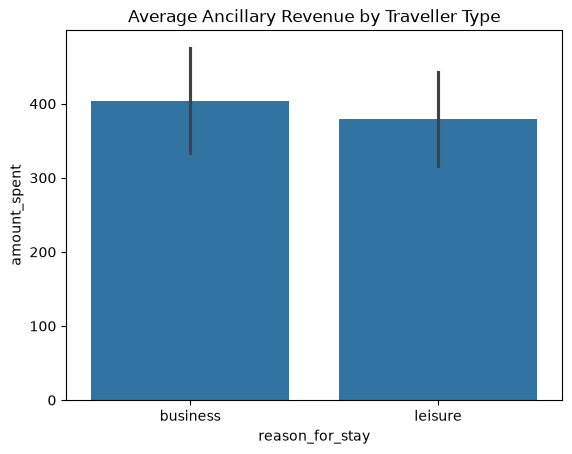

Average Ancillary Spent by Booking Channel：
Corporate: $414.14
Travel_Agent: $394.86
Website: $369.23
Corporate guests spend 12.2% more than Website guests


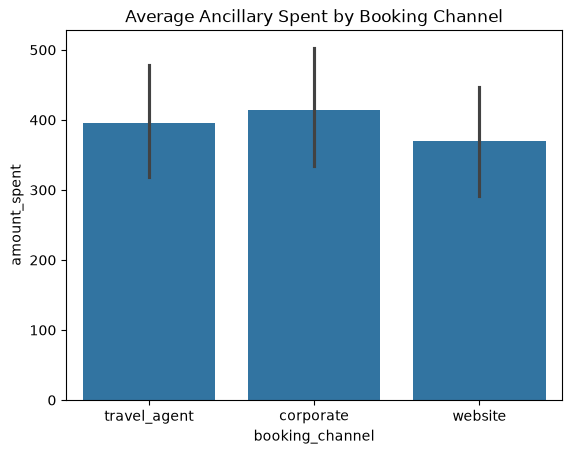

Average Ancillary Spent by Loyalty Tier：
Gold: $407.62
Platinum: $731.86
Silver: $404.09
Platinum members spent  81.1% more than Silver members


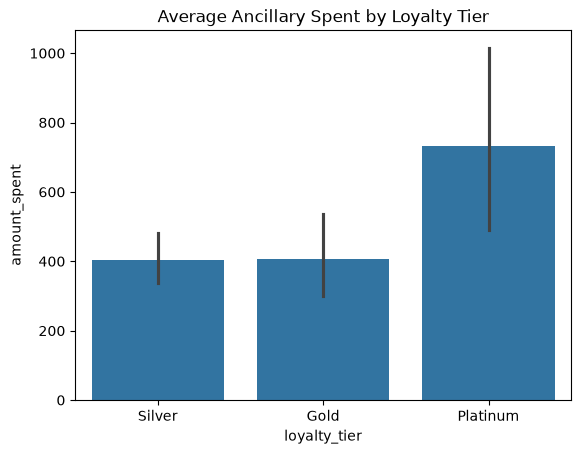

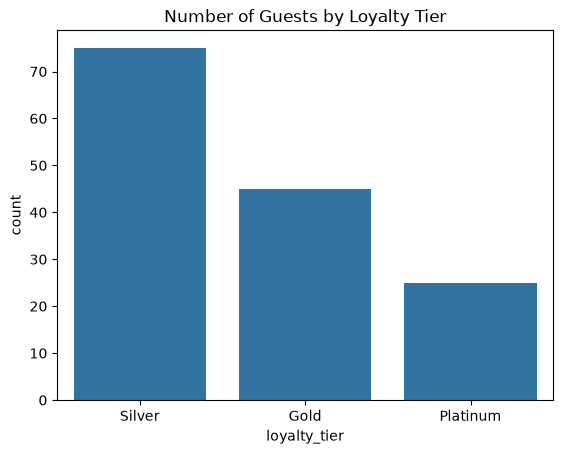

In [16]:
#most revenue traveller
revenue_traveller= round(guest_level.groupby('reason_for_stay')['amount_spent'].mean(),2)
print("Average Ancillary Revenue by Traveller Type:")
for traveller, revenue in revenue_traveller.items():
    print(f"{traveller.title()}: ${revenue}")

sns.barplot(data= guest_level,x='reason_for_stay', y='amount_spent')
plt.title('Average Ancillary Revenue by Traveller Type')
plt.show()

#most revenue booking channel
revenue_booking_channel= round(guest_level.groupby('booking_channel')['amount_spent'].mean(),2)
print(f"Average Ancillary Spent by Booking Channel：")
for channel,revenue in revenue_booking_channel.items():
    print(f"{channel.title()}: ${revenue}")

corporate_spend = revenue_booking_channel['corporate'] 
website_spend = revenue_booking_channel['website']
corporate_vs_website = (corporate_spend - website_spend) / website_spend
print(f"Corporate guests spend {corporate_vs_website:.1%} more than Website guests")

sns.barplot(data= guest_level,x='booking_channel', y='amount_spent')
plt.title('Average Ancillary Spent by Booking Channel')
plt.show()

#Revenue per Segment = 该组总收入 / 该组客人数
revenue_loyalty_tier= round(guest_level.groupby('loyalty_tier')['amount_spent'].mean(),2)
print(f"Average Ancillary Spent by Loyalty Tier：")
for loyalty,revenue in revenue_loyalty_tier.items():
    print(f"{loyalty.title()}: ${revenue}")

platinum_spend= revenue_loyalty_tier['Platinum']
silver_spend= revenue_loyalty_tier['Silver']
platinum_vs_silver= (platinum_spend-silver_spend)/silver_spend
print(f"Platinum members spent {platinum_vs_silver: .1%} more than Silver members")

sns.barplot(data= guest_level,x='loyalty_tier', y='amount_spent')
plt.title('Average Ancillary Spent by Loyalty Tier')
plt.show()

sns.countplot(
    data=guest_level,
    x='loyalty_tier'
)
plt.title('Number of Guests by Loyalty Tier')
plt.show()

## Ancillary Service Analysis

Average Ancillary Spent by Category：
Activities: $382.64
Dining: $422.84
Spa: $298.35


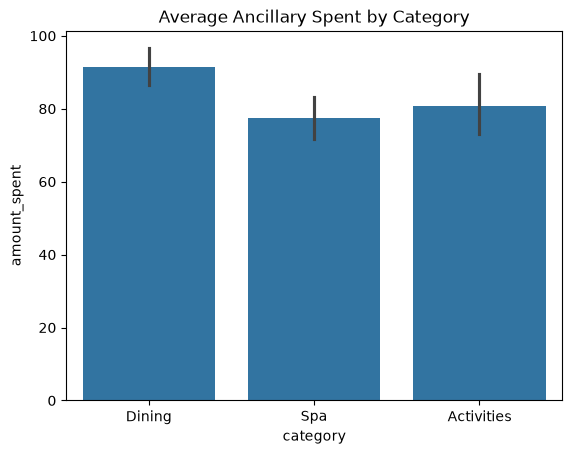

In [17]:
revenue_category= round(guest_level.groupby('category')['amount_spent'].mean(),2)
print(f"Average Ancillary Spent by Category：")
for category,revenue in revenue_category.items():
    print(f"{category.title()}: ${revenue}")
sns.barplot(data= hotel_merge,x='category', y='amount_spent')
plt.title('Average Ancillary Spent by Category')
plt.show()

## Segment Interaction Analysis

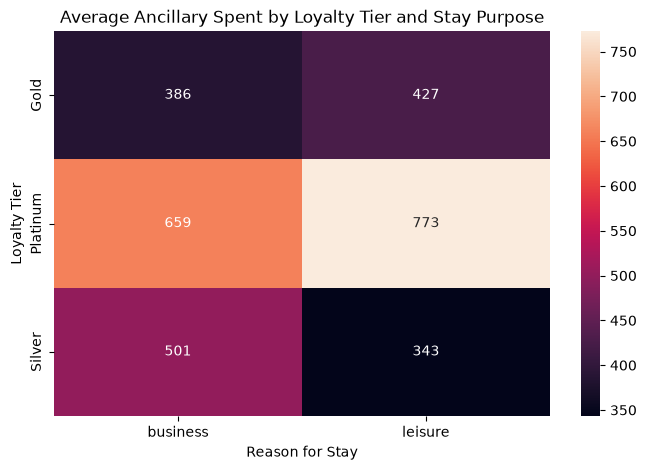

In [18]:
pivot= guest_level.pivot_table(index='loyalty_tier',columns= 'reason_for_stay',values= 'amount_spent',aggfunc= 'mean')
plt.figure(figsize=(8,5))
sns.heatmap(pivot,annot=True, fmt=".0f")
plt.title('Average Ancillary Spent by Loyalty Tier and Stay Purpose')
plt.xlabel('Reason for Stay')
plt.ylabel('Loyalty Tier')
plt.show()

## Key Findings

- Current Average Ancillary Revenue per Guest (ARPG) is $390.22
- Business travellers generate higher average ancillary spend than leisure travellers, indicating stronger upsell potential.
- Platinum members have the highest average ancillary spend, spending 81.1% more than Silver members.
- Guests booking through corporate channels generate 12.2% higher average ancillary spend compared with website bookings.
- Spending is highly concentrated among a small number of guests.
- The top 10% highest-spending guests contribute 35.31% of total ancillary revenue, showing revenue concentration among high-value guests.

### Recommendation 1

Target Platinum business travellers before arrival.

Because: Platinum highest ARPG & Business travellers highest spending

Action: 
- Create pre-arrival upsell campaigns targeting Platinum business travellers, offering dining credits, spa packages, and activity bundles before check-in.

### Recommendation 2

Optimise corporate booking channels with embedded ancillary packages.

Because: Corporate channel guests have 12.2% higher average ancillary spend than website bookings.

Action: 
- Add optional dining and activity bundles during corporate booking process
- Promote packages through corporate booking partners
- Include add-ons as part of business travel arrangements

### Recommendation 3

Create a VIP retention programme targeting the top 10% highest-spending guests with personalised offers and loyalty benefits.

Because: Top 10% guests generate 35% revenue.

Action:
- Exclusive dining experiences
- Spa packages
- Early access offers
- Personalised recommendations

## Conclusion
A small proportion of guests (top 10%) contribute approximately 35.31% of total ancillary revenue, indicating that revenue is concentrated among high-value customers.

To maximise ancillary revenue, Solstice Opal Hotel should focus on high-value guest segments, particularly Platinum members, business travellers, and corporate-channel guests. By combining targeted upselling strategies with VIP retention initiatives, the hotel can increase ancillary revenue while strengthening relationships with its most valuable customers.